Step 1: Mounting Google Drive

In [2]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


Step 2: Selecting a GPU runtime

In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("No GPU detected.")

PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


Step 3: Installing the required libraries

Why? These libraries provide:
- transformers: MedGemma inference pipeline
- accelerate: GPU model placement
- bitsandbytes: 4-bit model loading
- pandas: result tables and CSV files
- Pillow: BUSI image loading
- huggingface_hub: model access and revision tracking
- scikit-learn: classification metrics and confusion matrix
- seaborn: confusion-matrix visualization

No output may appear because -q enables quiet installation.

In [ ]:
%pip install -q -U \
    "transformers==5.20.2" \
    accelerate \
    "bitsandbytes==0.50.2" \
    "pandas==2.2.3" \
    "pillow==11.3.0" \
    "huggingface_hub>=1.32,<2.0" \
    scikit-learn \
    seaborn

Step 4: Checking the installed libraries

In [ ]:
import pandas as pd
import PIL
import torch
import transformers
import accelerate
import bitsandbytes as bnb
import sklearn
import seaborn as sns

from transformers.utils import (
    is_bitsandbytes_available
)

print("pandas:", pd.__version__)
print("Pillow:", PIL.__version__)
print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("Accelerate:", accelerate.__version__)
print("bitsandbytes:", bnb.__version__)
print("scikit-learn:", sklearn.__version__)
print("seaborn:", sns.__version__)

print("\nCUDA available:", torch.cuda.is_available())
print(
    "Transformers detects bitsandbytes:",
    is_bitsandbytes_available()
)

print("\nLibraries loaded successfully!")

pandas: 2.2.3
Pillow: 11.3.0
PyTorch: 2.11.0+cu130
Transformers: 5.20.2
Accelerate: 1.15.0
bitsandbytes: 0.50.2
scikit-learn: 1.9.1
seaborn: 0.13.2

CUDA available: True
Transformers detects bitsandbytes: True

Libraries loaded successfully!


Step 5: Logging in to Hugging Face

In [ ]:
from google.colab import userdata
from huggingface_hub import login, whoami

token = userdata.get("HF_TOKEN")

login(token=token)

print(
    "Logged in as:",
    whoami()["name"]
)

Logged in as: siyonanaik


Step 6: Loading the untouched BUSI evaluation split

In [ ]:
from pathlib import Path
import pandas as pd

evaluation_path = Path(
    "/content/drive/MyDrive/"
    "Ultrasound_Project-Siyona/"
    "data/splits/"
    "busi_test_760.csv"
)

evaluation_df = pd.read_csv(
    evaluation_path
)

existing_images = (
    evaluation_df["image_path"]
    .apply(
        lambda path: Path(path).exists()
    )
)

print("Evaluation split:")
print(evaluation_path)

print(
    "\nTotal evaluation images:",
    len(evaluation_df)
)

print(
    "Existing image files:",
    existing_images.sum(),
    "/",
    len(existing_images)
)

print("\nClass distribution:")
print(
    evaluation_df[
        "true_label"
    ].value_counts()
)

display(evaluation_df.head())

Evaluation split:
/content/drive/MyDrive/Ultrasound_Project-Siyona/data/splits/busi_test_760.csv

Total evaluation images: 760
Existing image files: 760 / 760

Class distribution:
true_label
benign       426
malignant    205
normal       129
Name: count, dtype: int64


,image_id,true_label,image_path,number_of_masks,mask_paths,split
0,normal (48).png,normal,/content/drive/MyDrive/Ultrasound_Project-Siyo...,1,/content/drive/MyDrive/Ultrasound_Project-Siyo...,test
1,benign (373).png,benign,/content/drive/MyDrive/Ultrasound_Project-Siyo...,1,/content/drive/MyDrive/Ultrasound_Project-Siyo...,test
2,benign (362).png,benign,/content/drive/MyDrive/Ultrasound_Project-Siyo...,1,/content/drive/MyDrive/Ultrasound_Project-Siyo...,test
3,normal (74).png,normal,/content/drive/MyDrive/Ultrasound_Project-Siyo...,1,/content/drive/MyDrive/Ultrasound_Project-Siyo...,test
4,benign (235).png,benign,/content/drive/MyDrive/Ultrasound_Project-Siyo...,1,/content/drive/MyDrive/Ultrasound_Project-Siyo...,test


Step 7: Checking that the development and evaluation splits do not overlap

Why? The 20 development images were used to compare decoding settings. They must not appear in the final 760-image evaluation, or the final results would no longer represent an untouched evaluation set.

In [ ]:
development_path = Path(
    "/content/drive/MyDrive/"
    "Ultrasound_Project-Siyona/"
    "data/splits/"
    "busi_development_20.csv"
)

development_df = pd.read_csv(
    development_path
)

overlapping_image_ids = set(
    development_df["image_id"]
).intersection(
    set(evaluation_df["image_id"])
)

print(
    "Development images:",
    len(development_df)
)

print(
    "Evaluation images:",
    len(evaluation_df)
)

print(
    "Overlapping image IDs:",
    len(overlapping_image_ids)
)

if overlapping_image_ids:
    print(
        "Overlap found:",
        sorted(overlapping_image_ids)
    )
else:
    print(
        "The development and evaluation "
        "splits are completely separate."
    )

Development images: 20
Evaluation images: 760
Overlapping image IDs: 0
The development and evaluation splits are completely separate.


Step 8: Loading the fixed BUSI classification prompt

Why? The full evaluation must use the exact same classification prompt used during the 20-image development experiment. Changing the prompt would introduce another experimental variable.

In [ ]:
prompt_path = Path(
    "/content/drive/MyDrive/"
    "Ultrasound_Project-Siyona/"
    "prompts/"
    "busi_classification_v1.txt"
)

PROMPT = prompt_path.read_text(
    encoding="utf-8"
)

print("Loaded prompt from:")
print(prompt_path)

print("\nPrompt contents:\n")
print(PROMPT)

Loaded prompt from:
/content/drive/MyDrive/Ultrasound_Project-Siyona/prompts/busi_classification_v1.txt

Prompt contents:

Classify this breast ultrasound image as exactly one of:
normal, benign lesion, malignant lesion, or insufficient image quality.

Return JSON only using this format:
{"label": "<allowed label>"}


Step 9: Loading MedGemma 1.5 4B

In [ ]:
import torch

from transformers import (
    BitsAndBytesConfig,
    pipeline
)

MODEL_ID = "google/medgemma-1.5-4b-it"

quantization_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_compute_dtype=torch.float16
)

medgemma = pipeline(
    task="image-text-to-text",
    model=MODEL_ID,
    device_map="auto",
    model_kwargs={
        "quantization_config":
            quantization_config
    }
)

print(
    "MedGemma loaded successfully!"
)

print(
    "Model:",
    MODEL_ID
)

config.json:   0%|          | 0.00/2.55k [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/90.6k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/883 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/115 [00:00<?, ?B/s]

... (5 outputs left out)

tokenizer.json: downloading bytes:           |  0.00B            

added_tokens.json:   0%|          | 0.00/35.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/662 [00:00<?, ?B/s]

MedGemma loaded successfully!
Model: google/medgemma-1.5-4b-it


Step 10: Recording the model revision and inference settings

In [ ]:
from huggingface_hub import model_info

model_revision = model_info(
    MODEL_ID
).sha

MAX_NEW_TOKENS = 60
DO_SAMPLE = False
TEMPERATURE = None
RANDOM_SEED = 42

print("Model:", MODEL_ID)
print("Revision:", model_revision)

print("\nInference settings:")
print("Maximum new tokens:", MAX_NEW_TOKENS)
print("Sampling enabled:", DO_SAMPLE)
print("Temperature:", TEMPERATURE)
print("Random seed:", RANDOM_SEED)

Model: google/medgemma-1.5-4b-it
Revision: 91850547d9f0b2fdd21aa7c5f4f3d1a8a52c243b

Inference settings:
Maximum new tokens: 60
Sampling enabled: False
Temperature: None
Random seed: 42


Step 11: Setting the random seed

In [ ]:
import random
import numpy as np
import torch

random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(
        RANDOM_SEED
    )

print(
    "Random seed set to:",
    RANDOM_SEED
)

Random seed set to: 42


Step 12: Creating the BUSI response parser

Why? MedGemma returns text, so the parser checks:
- Whether the response is valid JSON
- Whether it contains a label
- Whether the label is one of the four permitted BUSI outputs

The parser validates response structure, not medical correctness. Correctness will be checked separately against the true label.

In [ ]:
import json

ALLOWED_LABELS = {
    "normal",
    "benign lesion",
    "malignant lesion",
    "insufficient image quality"
}


def parse_busi_response(
    raw_response
):
    result = {
        "response_is_json": False,
        "predicted_label": None,
        "label_valid": False
    }

    try:
        parsed = json.loads(
            raw_response
        )
    except (
        json.JSONDecodeError,
        TypeError
    ):
        return result

    if not isinstance(parsed, dict):
        return result

    result["response_is_json"] = True

    predicted_label = parsed.get(
        "label"
    )

    result["predicted_label"] = (
        predicted_label
    )

    result["label_valid"] = (
        predicted_label
        in ALLOWED_LABELS
    )

    return result


print(
    "BUSI response parser created successfully!"
)

BUSI response parser created successfully!


Step 13: Creating the BUSI inference function

WHat is the inference function?
This function:
- Opens one BUSI image
- Converts it to RGB
- Sends the fixed prompt to MedGemma
- Uses greedy decoding
- Measures inference latency
- Returns the raw response
The function only defines the process. It does not run the 760-image evaluation yet.

In [ ]:
import time

from PIL import Image


def run_busi_inference(
    image_path
):
    image = Image.open(
        image_path
    ).convert("RGB")

    messages = [{
        "role": "user",
        "content": [
            {
                "type": "image",
                "image": image
            },
            {
                "type": "text",
                "text": PROMPT
            }
        ]
    }]

    start_time = time.perf_counter()

    output = medgemma(
        text=messages,
        max_new_tokens=MAX_NEW_TOKENS,
        generate_kwargs={
            "do_sample": DO_SAMPLE
        }
    )

    latency = (
        time.perf_counter()
        - start_time
    )

    raw_response = (
        output[0]["generated_text"][-1]["content"]
        .strip()
    )

    return raw_response, latency


print(
    "BUSI inference function created successfully!"
)

BUSI inference function created successfully!


Step 14: Testing one evaluation image

This checks that the full inference and parsing pipeline works on one image from the untouched evaluation split before starting the long run.

In [ ]:
label_mapping = {
    "normal": "normal",
    "benign": "benign lesion",
    "malignant": "malignant lesion"
}

test_row = evaluation_df.iloc[0]

raw_response, latency = run_busi_inference(
    test_row["image_path"]
)

parsed_response = parse_busi_response(
    raw_response
)

true_label = label_mapping[
    test_row["true_label"]
]

predicted_label = parsed_response[
    "predicted_label"
]

print("Image:", test_row["image_id"])
print("True label:", true_label)

print("\nRaw response:")
print(raw_response)

print("\nParsed response:")
print(parsed_response)

print(
    "\nCorrect:",
    predicted_label == true_label
)

print(
    "Latency:",
    round(latency, 2),
    "seconds"
)

Image: normal (48).png
True label: normal

Raw response:
{"label": "normal"}

Parsed response:
{'response_is_json': True, 'predicted_label': 'normal', 'label_valid': True}

Correct: True
Latency: 4.58 seconds


Step 15: Preparing the results folder and checkpoint

This creates a recoverable checkpoint system.
If Colab disconnects:
- Completed predictions remain saved in Google Drive.
- Rerunning this cell loads the checkpoint.
- The inference loop can skip images already processed.
- The evaluation continues instead of restarting from zero.

In [ ]:
results_folder = Path(
    "/content/drive/MyDrive/"
    "Ultrasound_Project-Siyona/"
    "results/busi_full_classification"
)

results_folder.mkdir(
    parents=True,
    exist_ok=True
)

checkpoint_path = (
    results_folder /
    "busi_test_760_greedy_checkpoint.csv"
)

final_results_path = (
    results_folder /
    "busi_test_760_greedy_medgemma.csv"
)

if checkpoint_path.exists():
    checkpoint_df = pd.read_csv(
        checkpoint_path
    )

    full_results = (
        checkpoint_df.to_dict(
            orient="records"
        )
    )

    print(
        "Existing checkpoint loaded."
    )
else:
    full_results = []

    print(
        "No existing checkpoint found. "
        "Starting a new evaluation."
    )

completed_image_ids = {
    result["image_id"]
    for result in full_results
}

print("\nResults folder:")
print(results_folder)

print(
    "\nPreviously completed images:",
    len(completed_image_ids)
)

print(
    "Images remaining:",
    len(evaluation_df)
    - len(completed_image_ids)
)

No existing checkpoint found. Starting a new evaluation.

Results folder:
/content/drive/MyDrive/Ultrasound_Project-Siyona/results/busi_full_classification

Previously completed images: 0
Images remaining: 760


Step 16: Running the complete 760-image BUSI evaluation

This cell:
- Processes every untouched BUSI evaluation image
- Skips images already present in a checkpoint
- Saves progress every 20 new images
- Saves immediately if an error occurs
- Creates the final results CSV only after all 760 images finish
- Prevents duplicate predictions when resuming

In [ ]:
CHECKPOINT_INTERVAL = 20
processed_this_session = 0

for _, row in evaluation_df.iterrows():
    image_id = row["image_id"]

    if image_id in completed_image_ids:
        continue

    try:
        raw_response, latency = (
            run_busi_inference(
                row["image_path"]
            )
        )

        parsed = parse_busi_response(
            raw_response
        )

        true_label = label_mapping[
            row["true_label"]
        ]

        predicted_label = parsed[
            "predicted_label"
        ]

        full_results.append({
            "dataset": "BUSI",
            "image_id": image_id,
            "image_path": row["image_path"],
            "true_label": true_label,
            "predicted_label":
                predicted_label,
            "raw_response": raw_response,
            "response_is_json":
                parsed["response_is_json"],
            "label_valid":
                parsed["label_valid"],
            "correct":
                predicted_label
                == true_label,
            "latency_seconds": latency,
            "prompt": PROMPT,
            "model_name": MODEL_ID,
            "model_revision":
                model_revision,
            "decoding_method": "greedy",
            "temperature": TEMPERATURE,
            "do_sample": DO_SAMPLE,
            "random_seed": RANDOM_SEED,
            "max_new_tokens":
                MAX_NEW_TOKENS
        })

        completed_image_ids.add(
            image_id
        )

        processed_this_session += 1

    except Exception as error:
        pd.DataFrame(
            full_results
        ).to_csv(
            checkpoint_path,
            index=False
        )

        print(
            "\nCheckpoint saved after an error."
        )

        print(
            "Failed image:",
            image_id
        )

        raise error

    if (
        processed_this_session
        % CHECKPOINT_INTERVAL
        == 0
    ):
        pd.DataFrame(
            full_results
        ).to_csv(
            checkpoint_path,
            index=False
        )

        print(
            f"Checkpoint saved: "
            f"{len(full_results)}/"
            f"{len(evaluation_df)} images"
        )

final_results_df = pd.DataFrame(
    full_results
)

final_results_df.to_csv(
    checkpoint_path,
    index=False
)

if len(final_results_df) == len(
    evaluation_df
):
    final_results_df.to_csv(
        final_results_path,
        index=False
    )

    print(
        "\nComplete evaluation saved to:"
    )

    print(final_results_path)

else:
    print(
        "\nThe run is incomplete. "
        "The checkpoint has been saved."
    )

print(
    "\nTotal completed images:",
    len(final_results_df)
)

print(
    "Images remaining:",
    len(evaluation_df)
    - len(final_results_df)
)

[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


Checkpoint saved: 20/760 images
Checkpoint saved: 40/760 images
Checkpoint saved: 60/760 images
Checkpoint saved: 80/760 images
Checkpoint saved: 100/760 images
Checkpoint saved: 120/760 images
Checkpoint saved: 140/760 images
Checkpoint saved: 160/760 images
Checkpoint saved: 180/760 images
Checkpoint saved: 200/760 images
Checkpoint saved: 220/760 images
Checkpoint saved: 240/760 images
Checkpoint saved: 260/760 images
Checkpoint saved: 280/760 images
Checkpoint saved: 300/760 images
Checkpoint saved: 320/760 images
Checkpoint saved: 340/760 images
Checkpoint saved: 360/760 images
Checkpoint saved: 380/760 images
Checkpoint saved: 400/760 images
Checkpoint saved: 420/760 images
Checkpoint saved: 440/760 images
Checkpoint saved: 460/760 images
Checkpoint saved: 480/760 images
Checkpoint saved: 500/760 images
Checkpoint saved: 520/760 images
Checkpoint saved: 540/760 images
Checkpoint saved: 560/760 images
Checkpoint saved: 580/760 images
Checkpoint saved: 600/760 images
Checkpoint sav

Step 17: Verifying the complete evaluation file

This confirms that:
- All 760 predictions were loaded successfully.
- Every image appears exactly once.
- No checkpoint duplication occurred.
- The true-label distribution still matches the evaluation split.
- Response validity is available for later metrics.

In [ ]:
final_results_df = pd.read_csv(
    final_results_path
)

duplicate_count = (
    final_results_df
    .duplicated(
        subset=["image_id"]
    )
    .sum()
)

print("Loaded final results from:")
print(final_results_path)

print(
    "\nTotal result rows:",
    len(final_results_df)
)

print(
    "Unique image IDs:",
    final_results_df[
        "image_id"
    ].nunique()
)

print(
    "Duplicate image IDs:",
    duplicate_count
)

print("\nTrue-label distribution:")
print(
    final_results_df[
        "true_label"
    ].value_counts()
)

print("\nValid-label responses:")
print(
    final_results_df[
        "label_valid"
    ].value_counts(
        dropna=False
    )
)

Loaded final results from:
/content/drive/MyDrive/Ultrasound_Project-Siyona/results/busi_full_classification/busi_test_760_greedy_medgemma.csv

Total result rows: 760
Unique image IDs: 760
Duplicate image IDs: 0

True-label distribution:
true_label
benign lesion       426
malignant lesion    205
normal              129
Name: count, dtype: int64

Valid-label responses:
label_valid
True     742
False     18
Name: count, dtype: int64


Step 18: Inspecting the invalid responses

An invalid response may mean:
- MedGemma returned prose instead of JSON.
- The JSON did not contain a label.
- The model returned a label outside the four permitted choices.
These responses should remain in the evaluation as invalid response rather than being silently removed. This ensures that the final metrics represent all 760 images.

In [ ]:
invalid_responses_df = (
    final_results_df[
        final_results_df[
            "label_valid"
        ] == False
    ][
        [
            "image_id",
            "true_label",
            "raw_response",
            "response_is_json",
            "predicted_label"
        ]
    ]
    .copy()
)

print(
    "Total invalid responses:",
    len(invalid_responses_df)
)

print("\nResponse JSON status:")

print(
    invalid_responses_df[
        "response_is_json"
    ].value_counts(
        dropna=False
    )
)

display(invalid_responses_df)

Total invalid responses: 18

Response JSON status:
response_is_json
False    18
Name: count, dtype: int64


,image_id,true_label,raw_response,response_is_json,predicted_label
38,malignant (31).png,malignant lesion,The image quality is insufficient.\n```json\n{...,False,NaN
105,benign (433).png,benign lesion,The image appears to show a breast ultrasound....,False,NaN
148,benign (140).png,benign lesion,"The image appears to show a large, dark, and s...",False,NaN
225,malignant (153).png,malignant lesion,The image appears to be a breast ultrasound. B...,False,NaN
254,malignant (61).png,malignant lesion,The image appears to show a breast ultrasound....,False,NaN
271,benign (236).png,benign lesion,The image shows a breast ultrasound. Based on ...,False,NaN
308,malignant (64).png,malignant lesion,The image appears to show a breast ultrasound....,False,NaN
325,malignant (198).png,malignant lesion,The image appears to be a breast ultrasound. B...,False,NaN
420,benign (368).png,benign lesion,The image appears to be a breast ultrasound. B...,False,NaN
432,malignant (30).png,malignant lesion,The image appears to be a breast ultrasound. B...,False,NaN


Step 19: Calculating the full classification metrics:

This calculates:
- Overall accuracy across all 760 images
- Correct-prediction count
- Valid-response rate
- Invalid-response count
- Insufficient-quality prediction count
- Average latency
- Precision, recall, and F1 score for each BUSI class
- Macro and weighted averages

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    classification_report
)

TARGET_LABELS = [
    "normal",
    "benign lesion",
    "malignant lesion"
]

final_results_df[
    "evaluation_prediction"
] = final_results_df[
    "predicted_label"
].where(
    final_results_df[
        "label_valid"
    ] == True,
    "invalid response"
)

overall_accuracy = accuracy_score(
    final_results_df["true_label"],
    final_results_df[
        "evaluation_prediction"
    ]
)

valid_label_rate = (
    final_results_df[
        "label_valid"
    ].mean()
)

insufficient_quality_count = (
    final_results_df[
        "evaluation_prediction"
    ]
    .eq(
        "insufficient image quality"
    )
    .sum()
)

invalid_response_count = (
    final_results_df[
        "evaluation_prediction"
    ]
    .eq(
        "invalid response"
    )
    .sum()
)

classification_report_dict = (
    classification_report(
        final_results_df["true_label"],
        final_results_df[
            "evaluation_prediction"
        ],
        labels=TARGET_LABELS,
        output_dict=True,
        zero_division=0
    )
)

metrics_table_df = (
    pd.DataFrame(
        classification_report_dict
    )
    .transpose()
)

evaluation_summary_df = pd.DataFrame([{
    "total_images":
        len(final_results_df),
    "correct_predictions":
        int(
            final_results_df[
                "correct"
            ].sum()
        ),
    "overall_accuracy":
        overall_accuracy,
    "valid_label_count":
        int(
            final_results_df[
                "label_valid"
            ].sum()
        ),
    "valid_label_rate":
        valid_label_rate,
    "invalid_response_count":
        int(invalid_response_count),
    "insufficient_quality_count":
        int(insufficient_quality_count),
    "average_latency_seconds":
        final_results_df[
            "latency_seconds"
        ].mean()
}])

print("Overall evaluation summary:")
display(evaluation_summary_df)

print("\nPer-class metrics:")
display(metrics_table_df)

Overall evaluation summary:


,total_images,correct_predictions,overall_accuracy,valid_label_count,valid_label_rate,invalid_response_count,insufficient_quality_count,average_latency_seconds
0,760,237,0.311842,742,0.976316,18,209,3.209064



Per-class metrics:


,precision,recall,f1-score,support
normal,0.276923,0.697674,0.396476,129.0
benign lesion,0.710145,0.345070,0.464455,426.0
malignant lesion,0.000000,0.000000,0.000000,205.0
micro avg,0.444653,0.311842,0.366589,760.0
macro avg,0.329023,0.347582,0.286977,760.0
weighted avg,0.445059,0.311842,0.327636,760.0


Step 20: Creating the BUSI confusion matrix

The confusion matrix shows exactly how every true BUSI class was classified, including insufficient image quality and invalid responses.

Confusion matrix counts:


evaluation_prediction,normal,benign lesion,malignant lesion,insufficient image quality,invalid response
true_label,,,,,
normal,90,1,0,38,0
benign lesion,180,147,1,92,6
malignant lesion,55,59,0,79,12


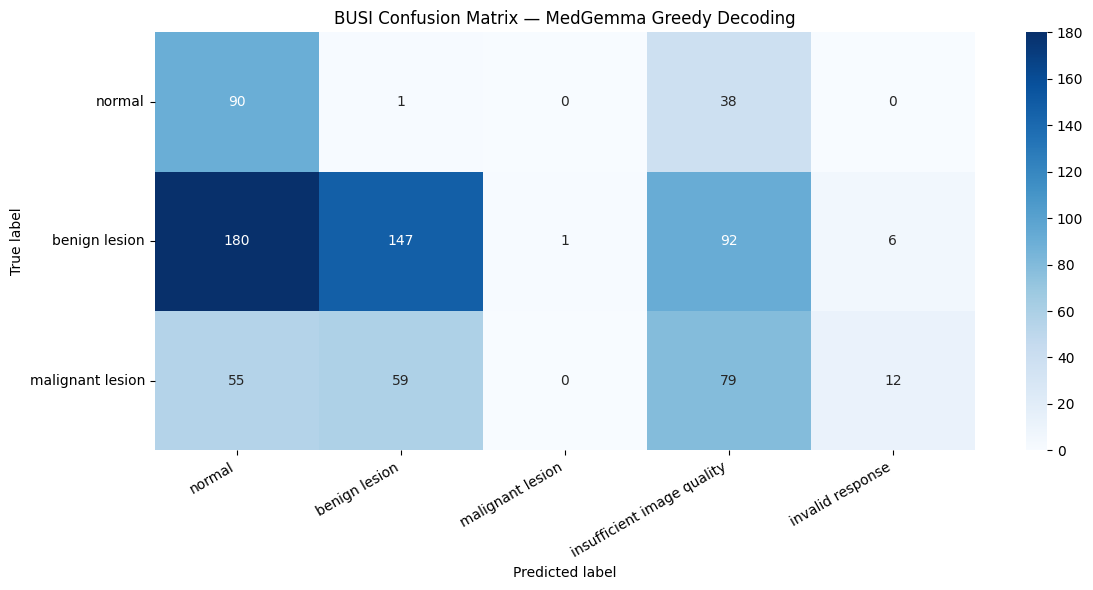

Saved confusion-matrix table to:
/content/drive/MyDrive/Ultrasound_Project-Siyona/results/busi_full_classification/busi_confusion_matrix_greedy.csv

Saved confusion-matrix image to:
/content/drive/MyDrive/Ultrasound_Project-Siyona/results/busi_full_classification/busi_confusion_matrix_greedy.png


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

PREDICTION_LABELS = [
    "normal",
    "benign lesion",
    "malignant lesion",
    "insufficient image quality",
    "invalid response"
]

confusion_table_df = pd.crosstab(
    final_results_df["true_label"],
    final_results_df[
        "evaluation_prediction"
    ]
).reindex(
    index=TARGET_LABELS,
    columns=PREDICTION_LABELS,
    fill_value=0
)

print("Confusion matrix counts:")
display(confusion_table_df)

confusion_csv_path = (
    results_folder /
    "busi_confusion_matrix_greedy.csv"
)

confusion_png_path = (
    results_folder /
    "busi_confusion_matrix_greedy.png"
)

confusion_table_df.to_csv(
    confusion_csv_path
)

plt.figure(
    figsize=(12, 6)
)

sns.heatmap(
    confusion_table_df,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=True
)

plt.title(
    "BUSI Confusion Matrix — "
    "MedGemma Greedy Decoding"
)

plt.xlabel(
    "Predicted label"
)

plt.ylabel(
    "True label"
)

plt.xticks(
    rotation=30,
    ha="right"
)

plt.yticks(
    rotation=0
)

plt.tight_layout()

plt.savefig(
    confusion_png_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved confusion-matrix table to:")
print(confusion_csv_path)

print("\nSaved confusion-matrix image to:")
print(confusion_png_path)

Step 21: Restoring the saved analysis data


In [3]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

results_folder = Path(
    "/content/drive/MyDrive/"
    "Ultrasound_Project-Siyona/"
    "results/busi_full_classification"
)

final_results_path = (
    results_folder /
    "busi_test_760_greedy_medgemma.csv"
)

final_results_df = pd.read_csv(
    final_results_path
)

final_results_df[
    "evaluation_prediction"
] = final_results_df[
    "predicted_label"
].where(
    final_results_df[
        "label_valid"
    ] == True,
    "invalid response"
)

TARGET_LABELS = [
    "normal",
    "benign lesion",
    "malignant lesion"
]

PREDICTION_LABELS = [
    "normal",
    "benign lesion",
    "malignant lesion",
    "insufficient image quality",
    "invalid response"
]

print(
    "Loaded result rows:",
    len(final_results_df)
)

print(
    "Unique images:",
    final_results_df[
        "image_id"
    ].nunique()
)

Loaded result rows: 760
Unique images: 760


Step 22: Comparing MedGemma with the majority-class baseline

Since benign lesions form the largest class, a simple classifier that predicts benign lesion for every image would achieve a measurable baseline accuracy.
This comparison shows whether MedGemma performs better than that basic strategy. The prediction distribution also reveals whether the model strongly favours or avoids particular labels.

In [4]:
prediction_distribution_df = (
    final_results_df[
        "evaluation_prediction"
    ]
    .value_counts()
    .reindex(
        PREDICTION_LABELS,
        fill_value=0
    )
    .rename_axis(
        "predicted_label"
    )
    .reset_index(
        name="prediction_count"
    )
)

prediction_distribution_df[
    "prediction_rate"
] = (
    prediction_distribution_df[
        "prediction_count"
    ]
    / len(final_results_df)
)

true_class_counts = (
    final_results_df[
        "true_label"
    ].value_counts()
)

majority_class = (
    true_class_counts.idxmax()
)

majority_baseline_accuracy = (
    true_class_counts.max()
    / len(final_results_df)
)

model_accuracy = (
    final_results_df[
        "correct"
    ].mean()
)

baseline_comparison_df = pd.DataFrame([{
    "model_accuracy":
        model_accuracy,
    "majority_class":
        majority_class,
    "majority_baseline_accuracy":
        majority_baseline_accuracy,
    "difference_from_baseline":
        model_accuracy
        - majority_baseline_accuracy
}])

print("Prediction distribution:")
display(prediction_distribution_df)

print("\nComparison with majority baseline:")
display(baseline_comparison_df)

Prediction distribution:


,predicted_label,prediction_count,prediction_rate
0,normal,325,0.427632
1,benign lesion,207,0.272368
2,malignant lesion,1,0.001316
3,insufficient image quality,209,0.275000
4,invalid response,18,0.023684



Comparison with majority baseline:


,model_accuracy,majority_class,majority_baseline_accuracy,difference_from_baseline
0,0.311842,benign lesion,0.560526,-0.248684


Step 23: Analysing errors by true class

This summarises the exact failure pattern for each true class, including:
- Class-specific accuracy
- Which alternative labels were selected
- How often the model abstained
- How often it produced an invalid response

The class-level analysis confirms:
- Normal images were handled best: 69.77% accuracy
- Benign accuracy was 34.51%
- Malignant accuracy was 0%
- Malignant images were most often classified as insufficient quality: 79/205
- Invalid responses were disproportionately malignant: 12/18

In [5]:
class_error_rows = []

for true_label, group in (
    final_results_df.groupby(
        "true_label"
    )
):
    class_error_rows.append({
        "true_label": true_label,
        "total_images": len(group),
        "correct_predictions":
            int(group["correct"].sum()),
        "class_accuracy":
            group["correct"].mean(),
        "predicted_normal":
            int(
                group[
                    "evaluation_prediction"
                ].eq("normal").sum()
            ),
        "predicted_benign":
            int(
                group[
                    "evaluation_prediction"
                ].eq(
                    "benign lesion"
                ).sum()
            ),
        "predicted_malignant":
            int(
                group[
                    "evaluation_prediction"
                ].eq(
                    "malignant lesion"
                ).sum()
            ),
        "insufficient_quality_count":
            int(
                group[
                    "evaluation_prediction"
                ].eq(
                    "insufficient image quality"
                ).sum()
            ),
        "insufficient_quality_rate":
            group[
                "evaluation_prediction"
            ].eq(
                "insufficient image quality"
            ).mean(),
        "invalid_response_count":
            int(
                group[
                    "evaluation_prediction"
                ].eq(
                    "invalid response"
                ).sum()
            ),
        "invalid_response_rate":
            group[
                "evaluation_prediction"
            ].eq(
                "invalid response"
            ).mean()
    })

class_error_analysis_df = pd.DataFrame(
    class_error_rows
)

display(class_error_analysis_df)

,true_label,total_images,correct_predictions,class_accuracy,predicted_normal,predicted_benign,predicted_malignant,insufficient_quality_count,insufficient_quality_rate,invalid_response_count,invalid_response_rate
0,benign lesion,426,147,0.345070,180,147,1,92,0.215962,6,0.014085
1,malignant lesion,205,0,0.000000,55,59,0,79,0.385366,12,0.058537
2,normal,129,90,0.697674,90,1,0,38,0.294574,0,0.000000


Step 24: Saving the complete Week 3 analysis tables


In [6]:
from sklearn.metrics import (
    accuracy_score,
    classification_report
)

overall_accuracy = accuracy_score(
    final_results_df["true_label"],
    final_results_df[
        "evaluation_prediction"
    ]
)

classification_report_dict = (
    classification_report(
        final_results_df["true_label"],
        final_results_df[
            "evaluation_prediction"
        ],
        labels=TARGET_LABELS,
        output_dict=True,
        zero_division=0
    )
)

metrics_table_df = (
    pd.DataFrame(
        classification_report_dict
    )
    .transpose()
    .rename_axis("metric")
    .reset_index()
)

evaluation_summary_df = pd.DataFrame([{
    "total_images":
        len(final_results_df),
    "correct_predictions":
        int(
            final_results_df[
                "correct"
            ].sum()
        ),
    "overall_accuracy":
        overall_accuracy,
    "valid_label_count":
        int(
            final_results_df[
                "label_valid"
            ].sum()
        ),
    "valid_label_rate":
        final_results_df[
            "label_valid"
        ].mean(),
    "invalid_response_count":
        int(
            final_results_df[
                "evaluation_prediction"
            ].eq(
                "invalid response"
            ).sum()
        ),
    "insufficient_quality_count":
        int(
            final_results_df[
                "evaluation_prediction"
            ].eq(
                "insufficient image quality"
            ).sum()
        ),
    "average_latency_seconds":
        final_results_df[
            "latency_seconds"
        ].mean(),
    "majority_class":
        majority_class,
    "majority_baseline_accuracy":
        majority_baseline_accuracy,
    "difference_from_baseline":
        model_accuracy
        - majority_baseline_accuracy
}])

confusion_table_df = pd.crosstab(
    final_results_df["true_label"],
    final_results_df[
        "evaluation_prediction"
    ]
).reindex(
    index=TARGET_LABELS,
    columns=PREDICTION_LABELS,
    fill_value=0
)

invalid_responses_df = (
    final_results_df[
        final_results_df[
            "label_valid"
        ] == False
    ][
        [
            "image_id",
            "true_label",
            "raw_response",
            "response_is_json",
            "predicted_label"
        ]
    ]
    .copy()
)

evaluation_summary_path = (
    results_folder /
    "busi_full_evaluation_summary.csv"
)

metrics_table_path = (
    results_folder /
    "busi_per_class_metrics.csv"
)

prediction_distribution_path = (
    results_folder /
    "busi_prediction_distribution.csv"
)

baseline_comparison_path = (
    results_folder /
    "busi_majority_baseline_comparison.csv"
)

class_error_analysis_path = (
    results_folder /
    "busi_class_error_analysis.csv"
)

invalid_responses_path = (
    results_folder /
    "busi_full_invalid_responses.csv"
)

confusion_table_path = (
    results_folder /
    "busi_confusion_matrix_greedy.csv"
)

evaluation_summary_df.to_csv(
    evaluation_summary_path,
    index=False
)

metrics_table_df.to_csv(
    metrics_table_path,
    index=False
)

prediction_distribution_df.to_csv(
    prediction_distribution_path,
    index=False
)

baseline_comparison_df.to_csv(
    baseline_comparison_path,
    index=False
)

class_error_analysis_df.to_csv(
    class_error_analysis_path,
    index=False
)

invalid_responses_df.to_csv(
    invalid_responses_path,
    index=False
)

confusion_table_df.to_csv(
    confusion_table_path
)

print("Saved Week 3 analysis files:")

for saved_path in [
    evaluation_summary_path,
    metrics_table_path,
    prediction_distribution_path,
    baseline_comparison_path,
    class_error_analysis_path,
    invalid_responses_path,
    confusion_table_path
]:
    print("-", saved_path.name)

Saved Week 3 analysis files:
- busi_full_evaluation_summary.csv
- busi_per_class_metrics.csv
- busi_prediction_distribution.csv
- busi_majority_baseline_comparison.csv
- busi_class_error_analysis.csv
- busi_full_invalid_responses.csv
- busi_confusion_matrix_greedy.csv


Step 25: Loading the decoding comparison into the Week 3 analysis

In [7]:
temperature_comparison_path = Path(
    "/content/drive/MyDrive/"
    "Ultrasound_Project-Siyona/"
    "results/temperature_experiment/"
    "busi_greedy_vs_temperature_comparison.csv"
)

decoding_comparison_df = pd.read_csv(
    temperature_comparison_path
)

decoding_comparison_df.insert(
    0,
    "evaluation_scope",
    "20-image development subset"
)

week3_decoding_path = (
    results_folder /
    "busi_development_decoding_comparison.csv"
)

decoding_comparison_df.to_csv(
    week3_decoding_path,
    index=False
)

print("Development decoding comparison:")
display(decoding_comparison_df)

print("\nSaved Week 3 copy to:")
print(week3_decoding_path)

Development decoding comparison:


,evaluation_scope,condition,temperature,do_sample,total_runs,valid_json_count,valid_json_rate,correct_predictions,overall_accuracy,average_latency_seconds,valid_response_accuracy,insufficient_quality_rate
0,20-image development subset,greedy,NaN,False,20,20,1.00,5,0.25,3.021355,0.250000,0.35
1,20-image development subset,sampling_temperature_0.1,0.1,True,20,20,1.00,5,0.25,3.290276,0.250000,0.30
2,20-image development subset,sampling_temperature_0.3,0.3,True,20,13,0.65,3,0.15,4.614020,0.230769,0.15
3,20-image development subset,sampling_temperature_0.7,0.7,True,20,11,0.55,2,0.10,4.937509,0.181818,0.25
4,20-image development subset,sampling_temperature_1.0,1.0,True,20,8,0.40,3,0.15,4.201616,0.375000,0.05



Saved Week 3 copy to:
/content/drive/MyDrive/Ultrasound_Project-Siyona/results/busi_full_classification/busi_development_decoding_comparison.csv


| Week 3 requirement | Completed evidence |
|---|---|
| Complete BUSI clean-image classification | Greedy inference on all 760 untouched evaluation images |
| Metrics table | Overall and per-class metrics CSVs |
| Confusion matrix | Saved as CSV and PNG |
| Raw-output log | All 760 responses in `busi_test_760_greedy_medgemma.csv` |
| Temperature and greedy analysis | Five-condition comparison on the fixed 20-image development subset |